# Manufacturing Process Analytics
## Phase 1: synthetic demonstration data
All observations are synthetic. This notebook reuses the tested project functions. No real employer data, causal claims, or optimization are included.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.run_pipeline import main
from src.data_quality import validate_data
main()

{
  "rows": 3000,
  "means": {
    "yield_percent": 92.50573333333335,
    "defect_rate_percent": 6.155166666666666,
    "energy_kWh": 36.425095666666664
  },
  "regions": {
    "candidate_screen": {
      "batch_count": 330,
      "yield_percent": 95.63181818181818,
      "defect_rate_percent": 2.971212121212121,
      "energy_kWh": 37.522245454545455
    },
    "outside_candidate_screen": {
      "batch_count": 2670,
      "yield_percent": 92.11936329588015,
      "defect_rate_percent": 6.548689138576779,
      "energy_kWh": 36.28949288389513
    },
    "short_cycle": {
      "batch_count": 194,
      "yield_percent": 83.62422680412371,
      "defect_rate_percent": 15.157731958762888,
      "energy_kWh": 31.21501030927835
    },
    "outside_short_cycle": {
      "batch_count": 2806,
      "yield_percent": 93.11977904490378,
      "defect_rate_percent": 5.532751247327155,
      "energy_kWh": 36.78530826799715
    },
    "temperature_tails": {
      "batch_count": 301,
      "yield_pe

## 1. Validate persisted batches
Each batch has 1,000 input units. First-pass yield, tracked defects, and other losses are disjoint and sum to 100%.

In [2]:
data = pd.read_csv(ROOT / "data/raw/synthetic_batches.csv", parse_dates=["timestamp"])
display(pd.Series(validate_data(data), name="passed"))
display(data.head())
display(data.describe())

exact_schema                      True
expected_row_count                True
no_missing_values                 True
no_duplicate_rows                 True
string_dtypes                     True
numeric_dtypes                    True
timestamp_dtype                   True
sequential_batch_ids              True
timestamp_start                   True
timestamp_cadence                 True
timestamps_strictly_increasing    True
valid_materials                   True
valid_machines                    True
synthetic_label                   True
temperature_C_range               True
pressure_MPa_range                True
cycle_time_min_range              True
yield_percent_range               True
defect_rate_percent_range         True
other_loss_percent_range          True
energy_kWh_range                  True
unit_balance                      True
Name: passed, dtype: bool

,batch_id,timestamp,material_type,machine_id,temperature_C,pressure_MPa,cycle_time_min,yield_percent,defect_rate_percent,other_loss_percent,energy_kWh,data_origin
0,B00001,2025-01-01 00:00:00,B,M2,183.24,5.429,12.92,98.3,1.1,0.6,41.319,synthetic_demonstration
1,B00002,2025-01-01 00:30:00,A,M3,174.43,5.681,12.76,95.2,3.3,1.5,35.771,synthetic_demonstration
2,B00003,2025-01-01 01:00:00,C,M2,165.73,4.427,12.14,96.7,1.1,2.2,34.627,synthetic_demonstration
3,B00004,2025-01-01 01:30:00,B,M2,167.25,5.013,13.59,93.6,4.6,1.8,33.664,synthetic_demonstration
4,B00005,2025-01-01 02:00:00,A,M2,179.42,5.138,8.86,95.5,3.4,1.1,32.514,synthetic_demonstration


,timestamp,temperature_C,pressure_MPa,cycle_time_min,yield_percent,defect_rate_percent,other_loss_percent,energy_kWh
count,3000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,2025-02-01 05:45:00.000000512,180.590297,4.975755,11.958940,92.505733,6.155167,1.339100,36.425096
min,2025-01-01 00:00:00,140.000000,2.500000,6.000000,50.900000,0.500000,0.000000,20.812000
25%,2025-01-16 14:52:30,172.517500,4.477750,10.630000,91.600000,2.900000,0.900000,33.108750
50%,2025-02-01 05:45:00,180.340000,4.964000,11.930000,94.200000,4.300000,1.300000,36.244500
75%,2025-02-16 20:37:30,188.685000,5.481250,13.290000,95.700000,7.000000,1.700000,39.408250
max,2025-03-04 11:30:00,220.000000,7.500000,19.000000,99.000000,48.100000,4.300000,55.204000
std,NaN,12.157096,0.759246,1.990742,5.744764,5.798343,0.597233,4.810887


## 2. Compare distributions and groups
Inspect spread as well as means. Machine and material averages are unadjusted descriptive comparisons.

yield_percent                      defect_rate_percent            \
                   count       mean       std               count      mean   
machine_id                                                                    
M1                  1050  93.177524  5.630704                1050  5.484095   
M2                   993  92.547331  5.439361                 993  6.092346   
M3                   957  91.725496  6.077207                 957  6.956635   

                     energy_kWh                       
                 std      count       mean       std  
machine_id                                            
M1          5.679806       1050  35.371613  4.639413  
M2          5.499745        993  36.230151  4.702268  
M3          6.127231        957  37.783232  4.789414

yield_percent                      defect_rate_percent  \
                      count       mean       std               count   
material_type                                                          
A                      1355  92.643247  5.458372                1355   
B                      1036  92.264961  6.254640                1036   
C                       609  92.609360  5.448792                 609   

                                  energy_kWh                       
                   mean       std      count       mean       std  
material_type                                                      
A              6.012694  5.500125       1355  36.371993  4.769792  
B              6.387838  6.310596       1036  36.763144  4.796672  
C              6.076355  5.525592        609  35.968176  4.890797

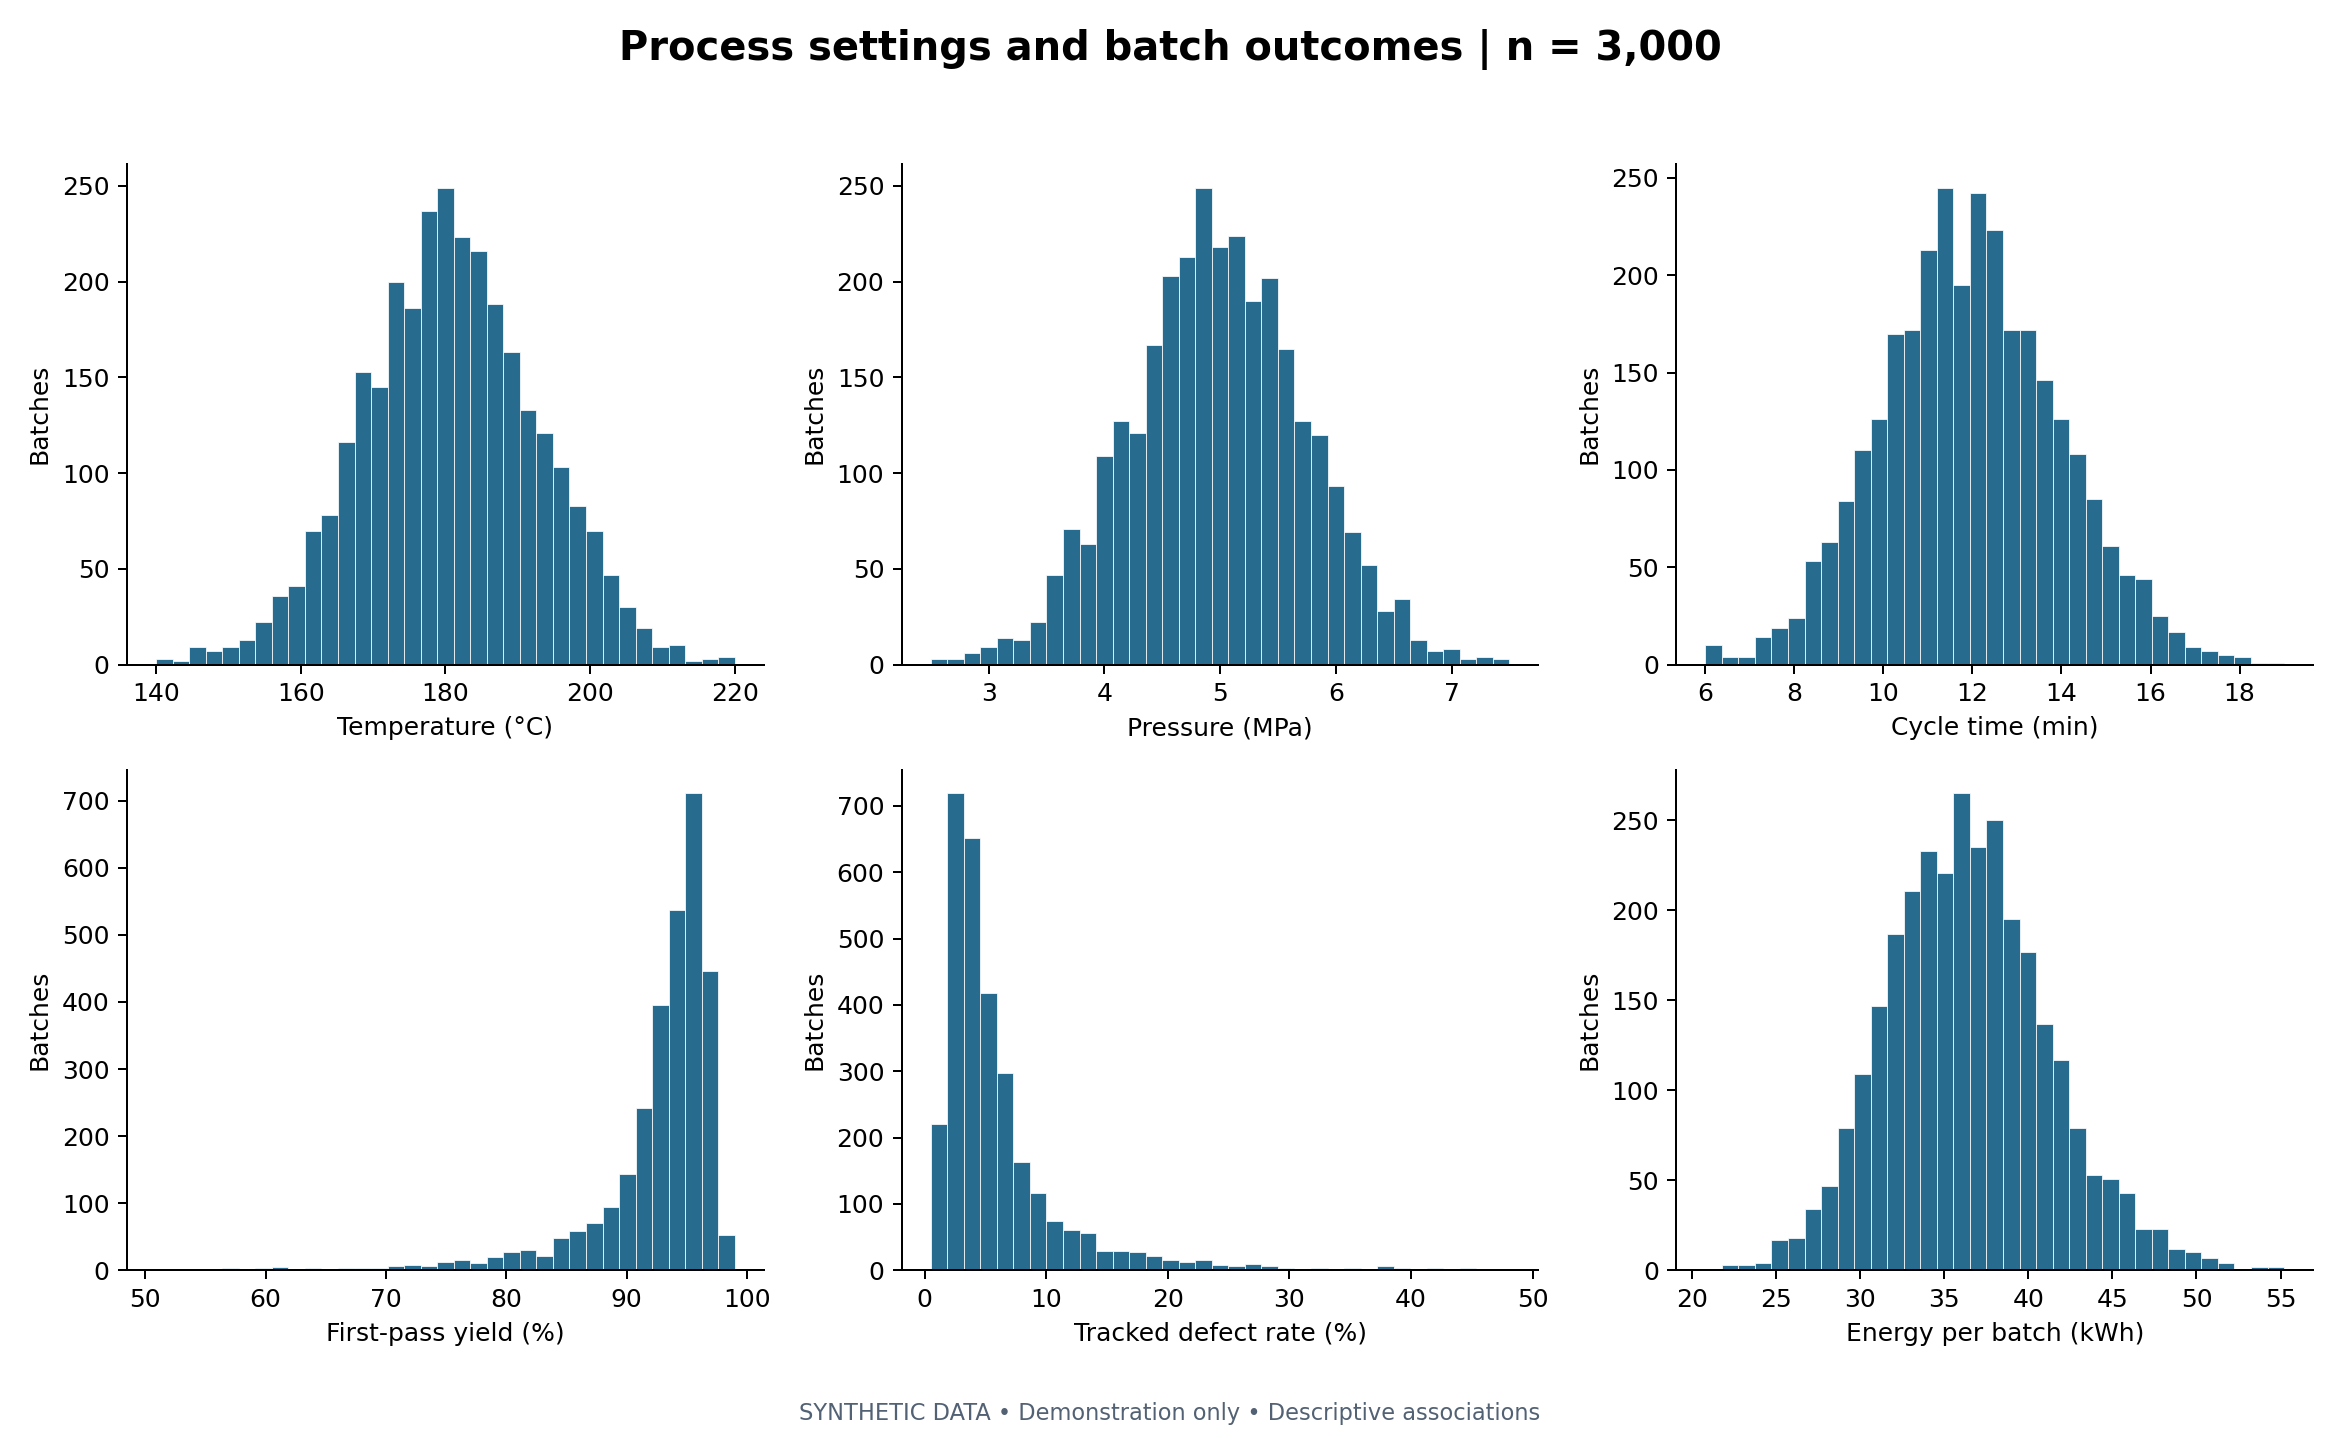

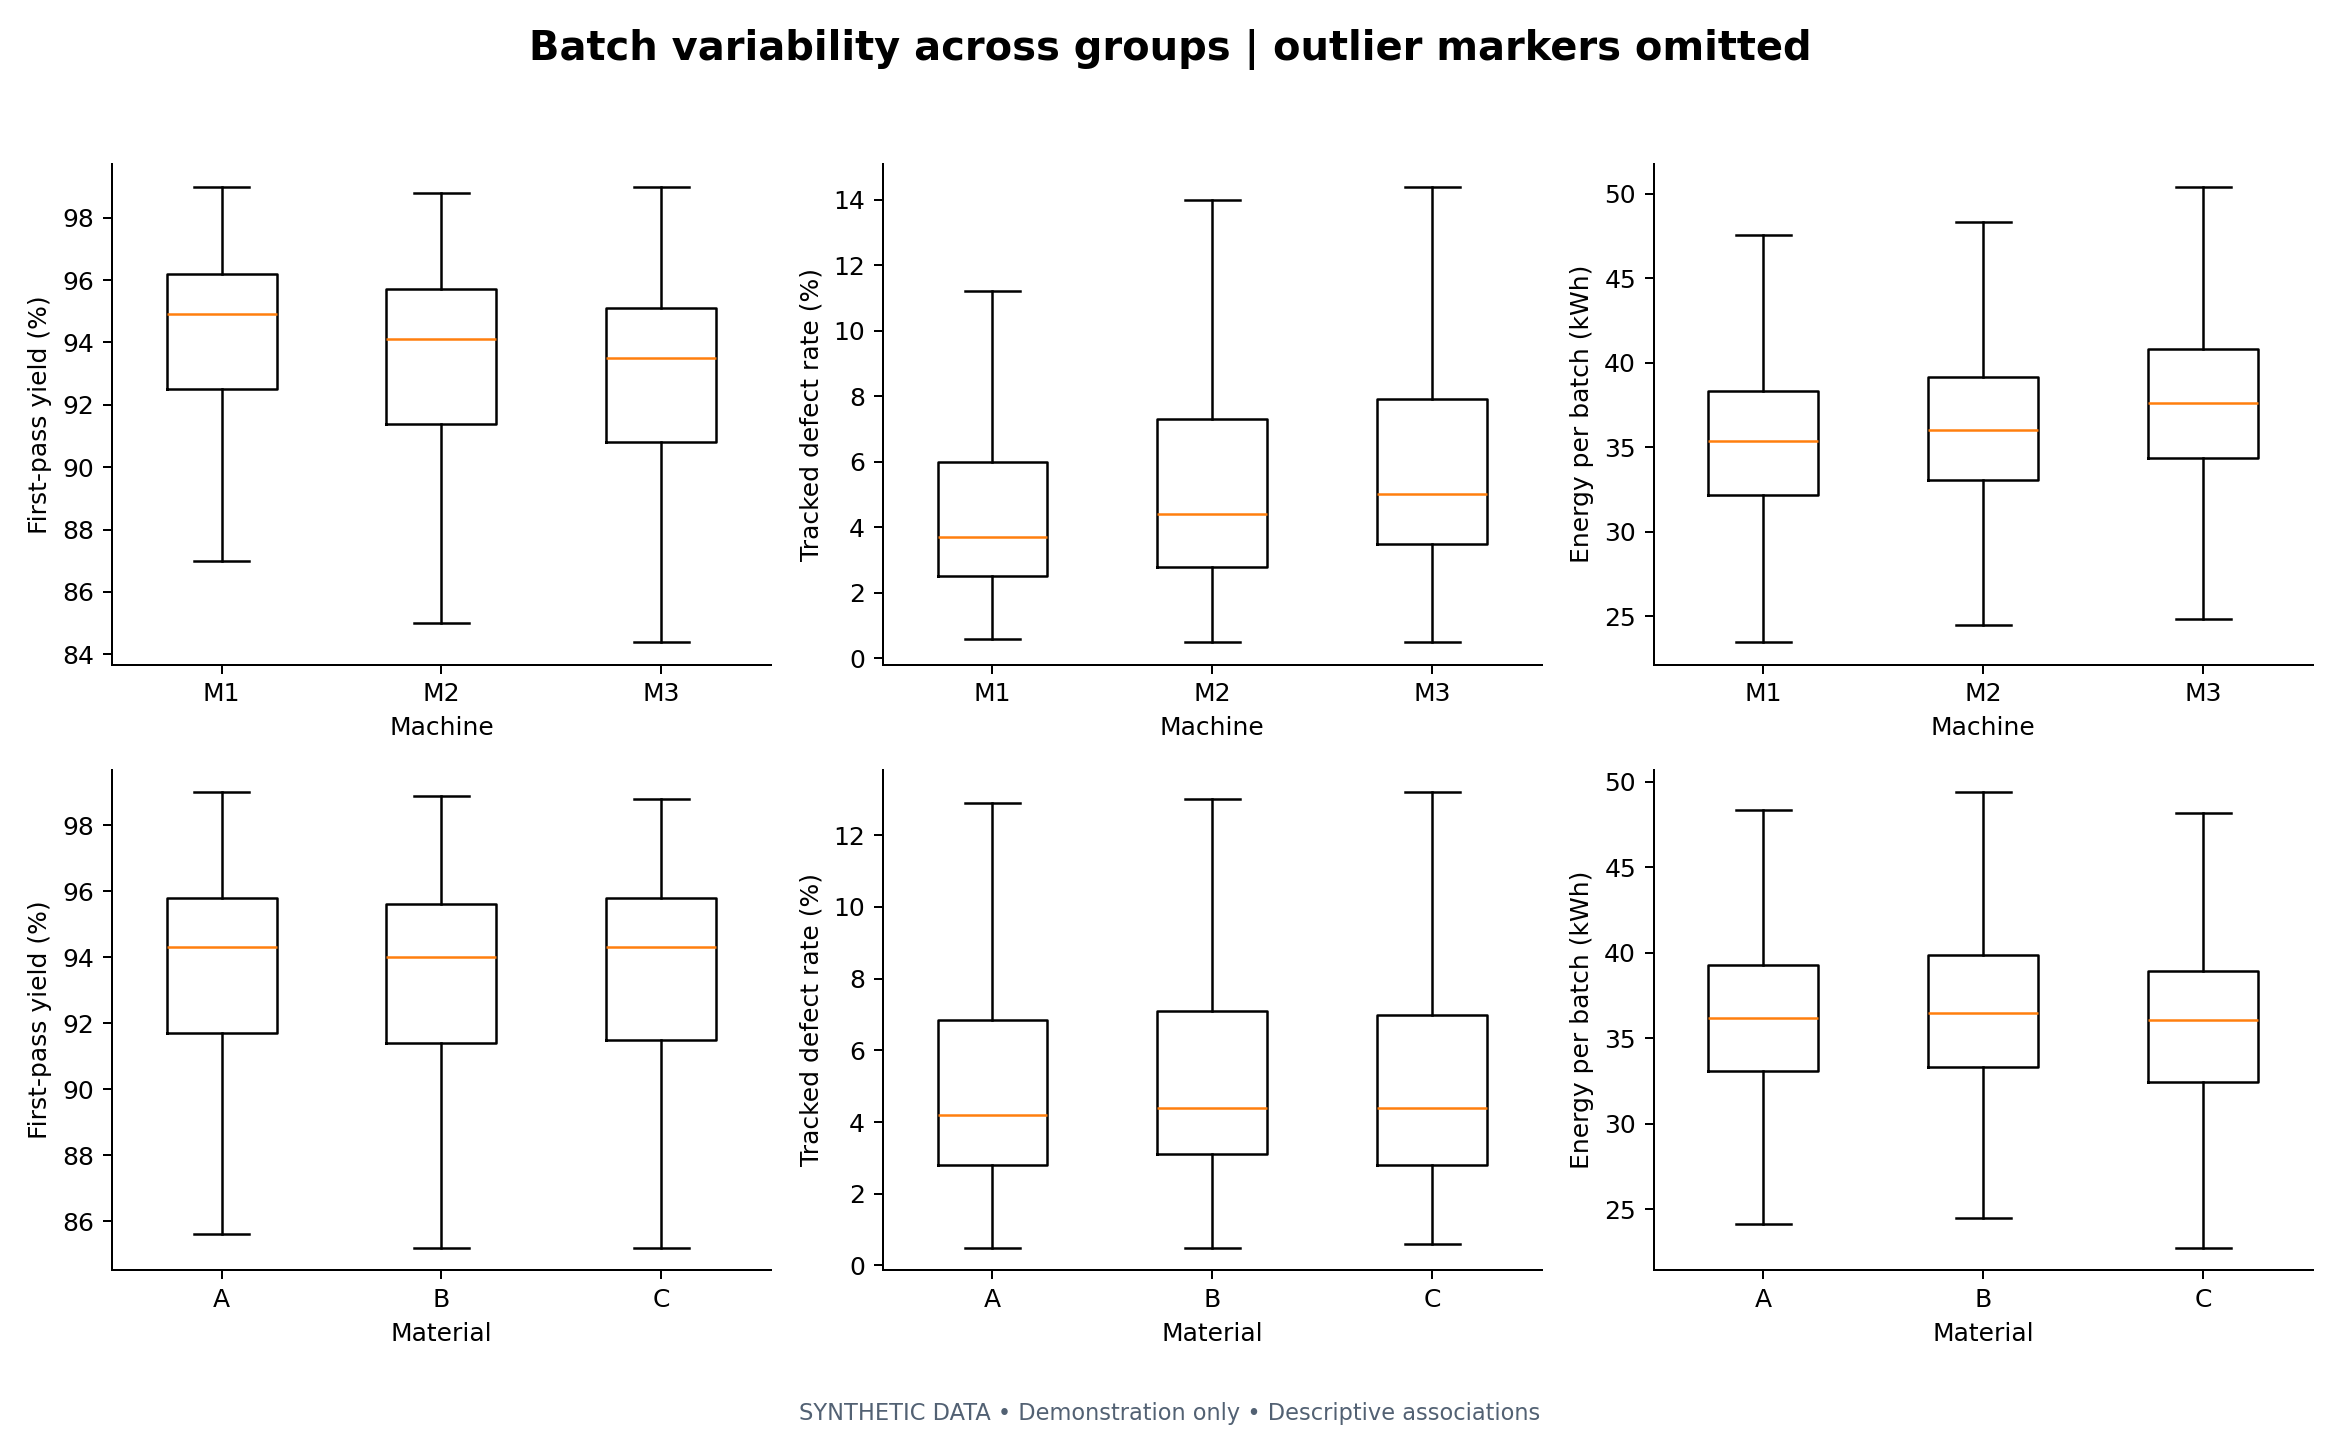

In [3]:
from src.analysis import OUTCOMES
for group in ["machine_id", "material_type"]:
    display(data.groupby(group)[OUTCOMES].agg(["count", "mean", "std"]))
for name in ["distributions", "group_comparisons"]:
    display(Image(filename=str(ROOT / "figures" / f"{name}.png")))

## 3. Explore process relationships
Squared response terms create nonlinear associations. A near-zero Pearson correlation does not imply that a setting has no relationship with defects. Yield and defects are linked by the unit balance.

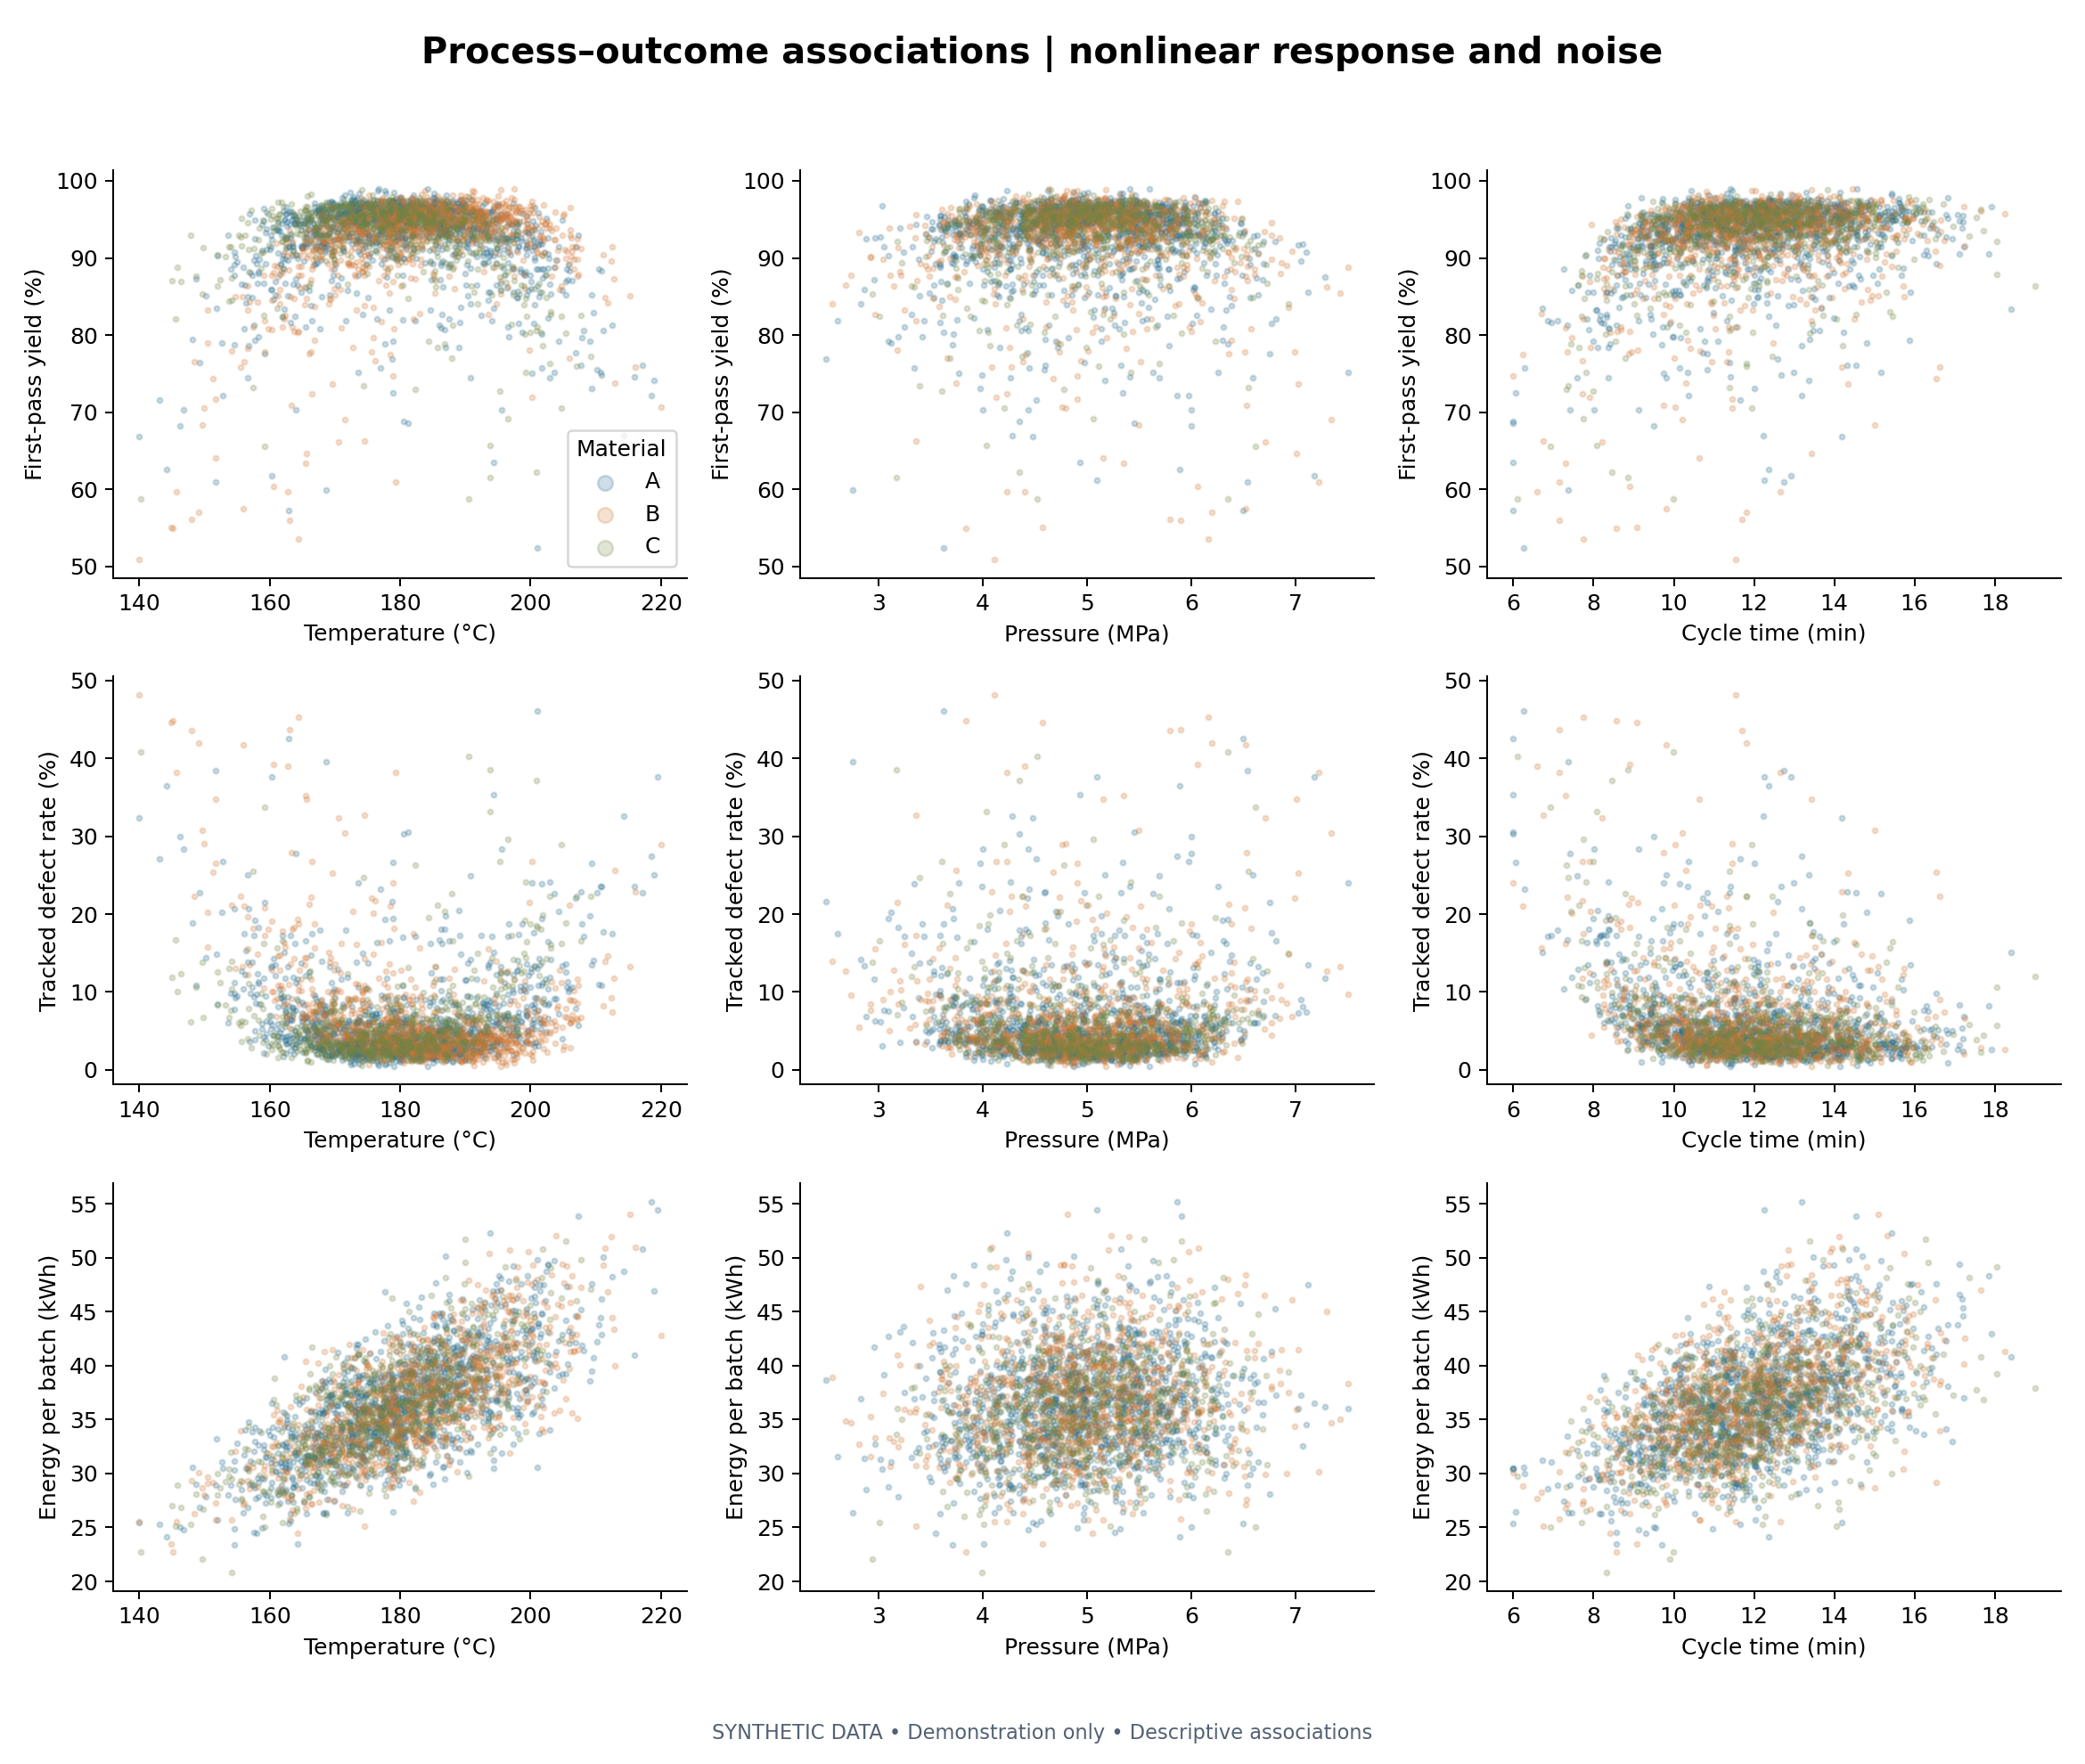

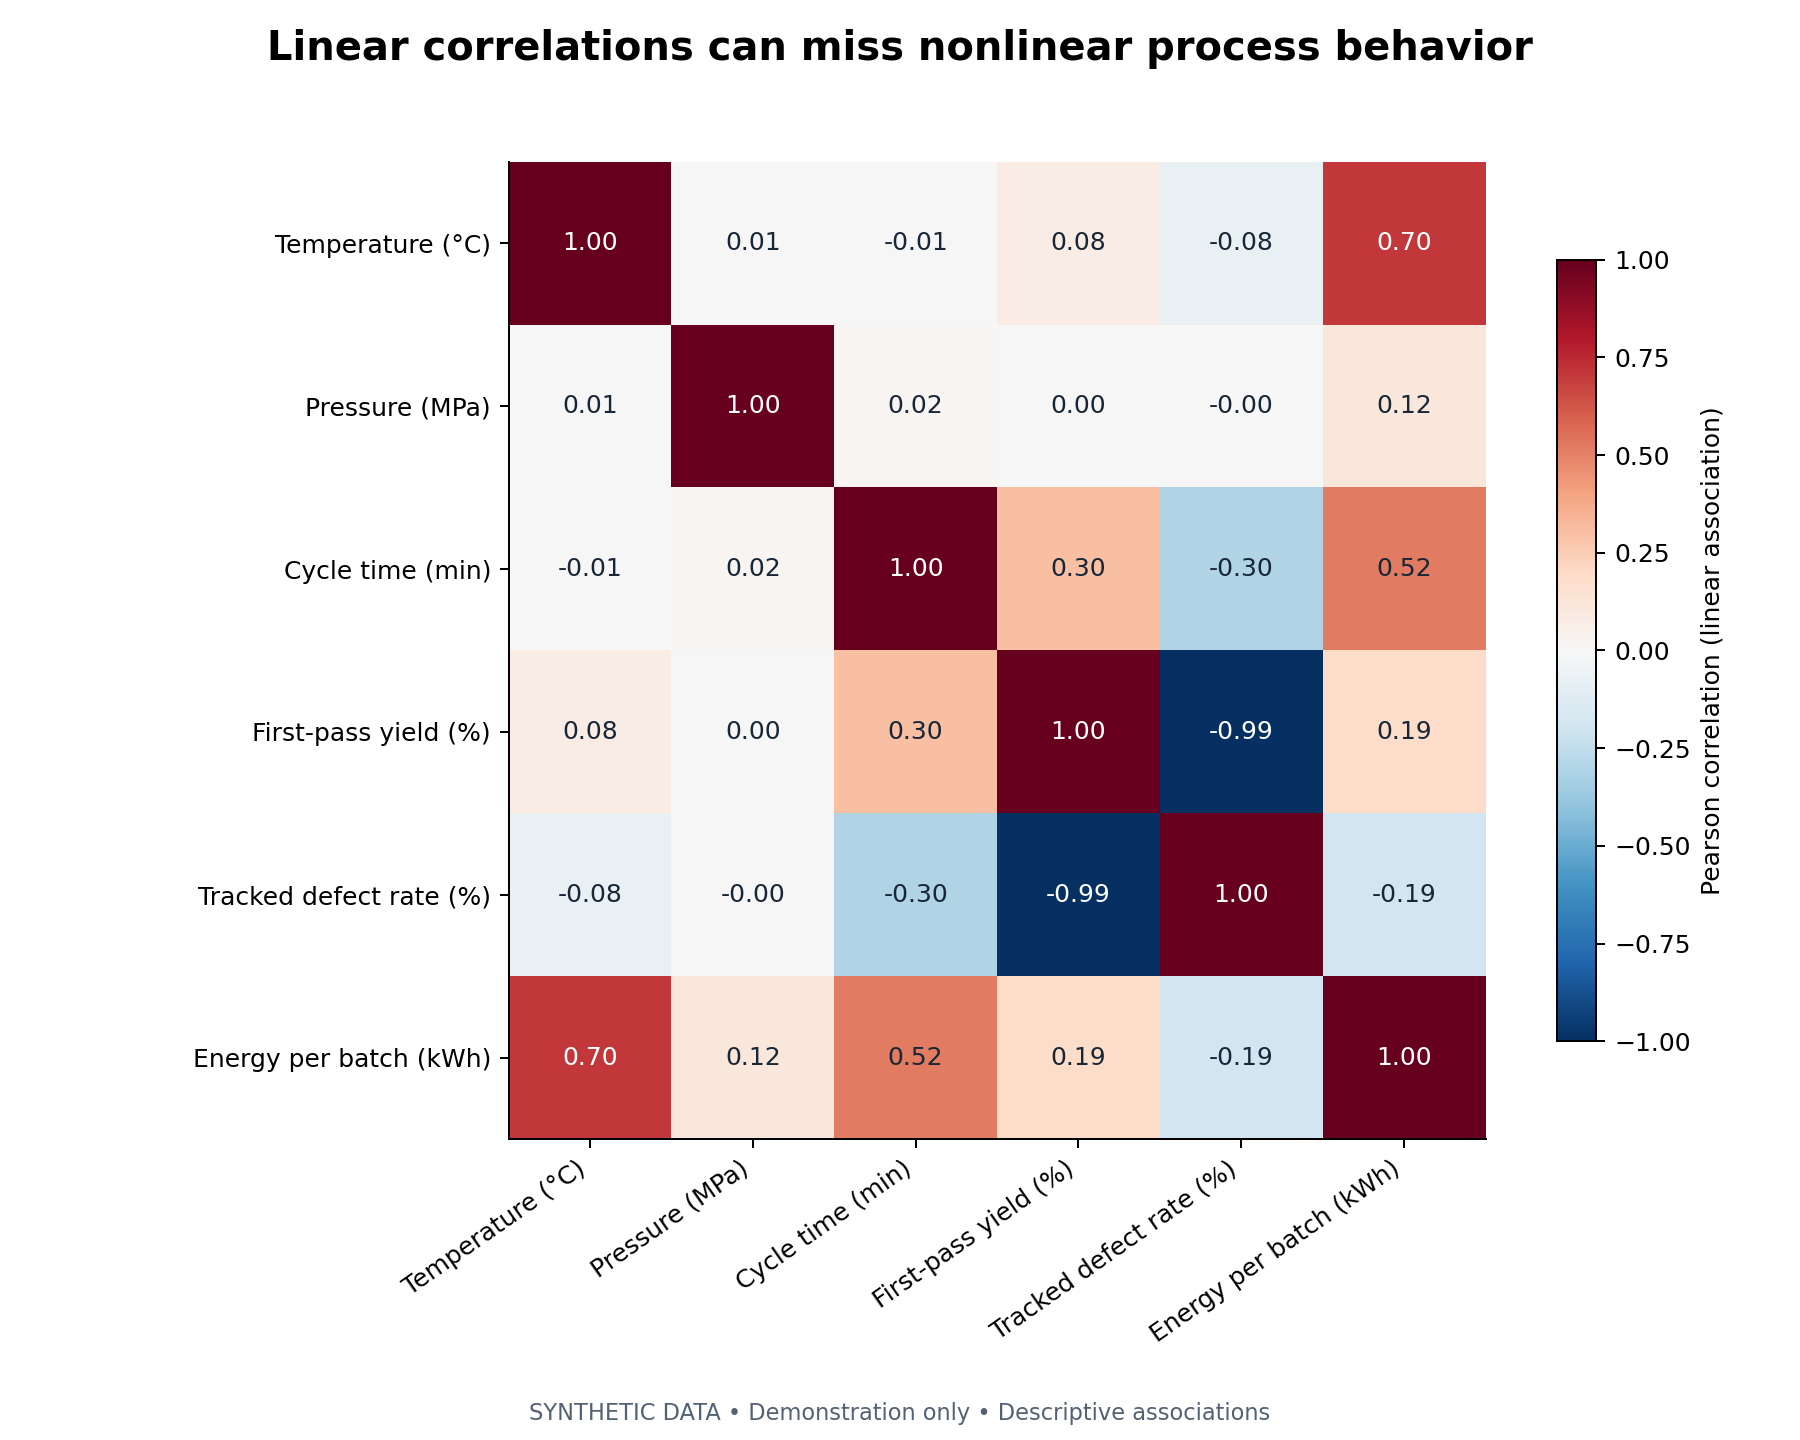

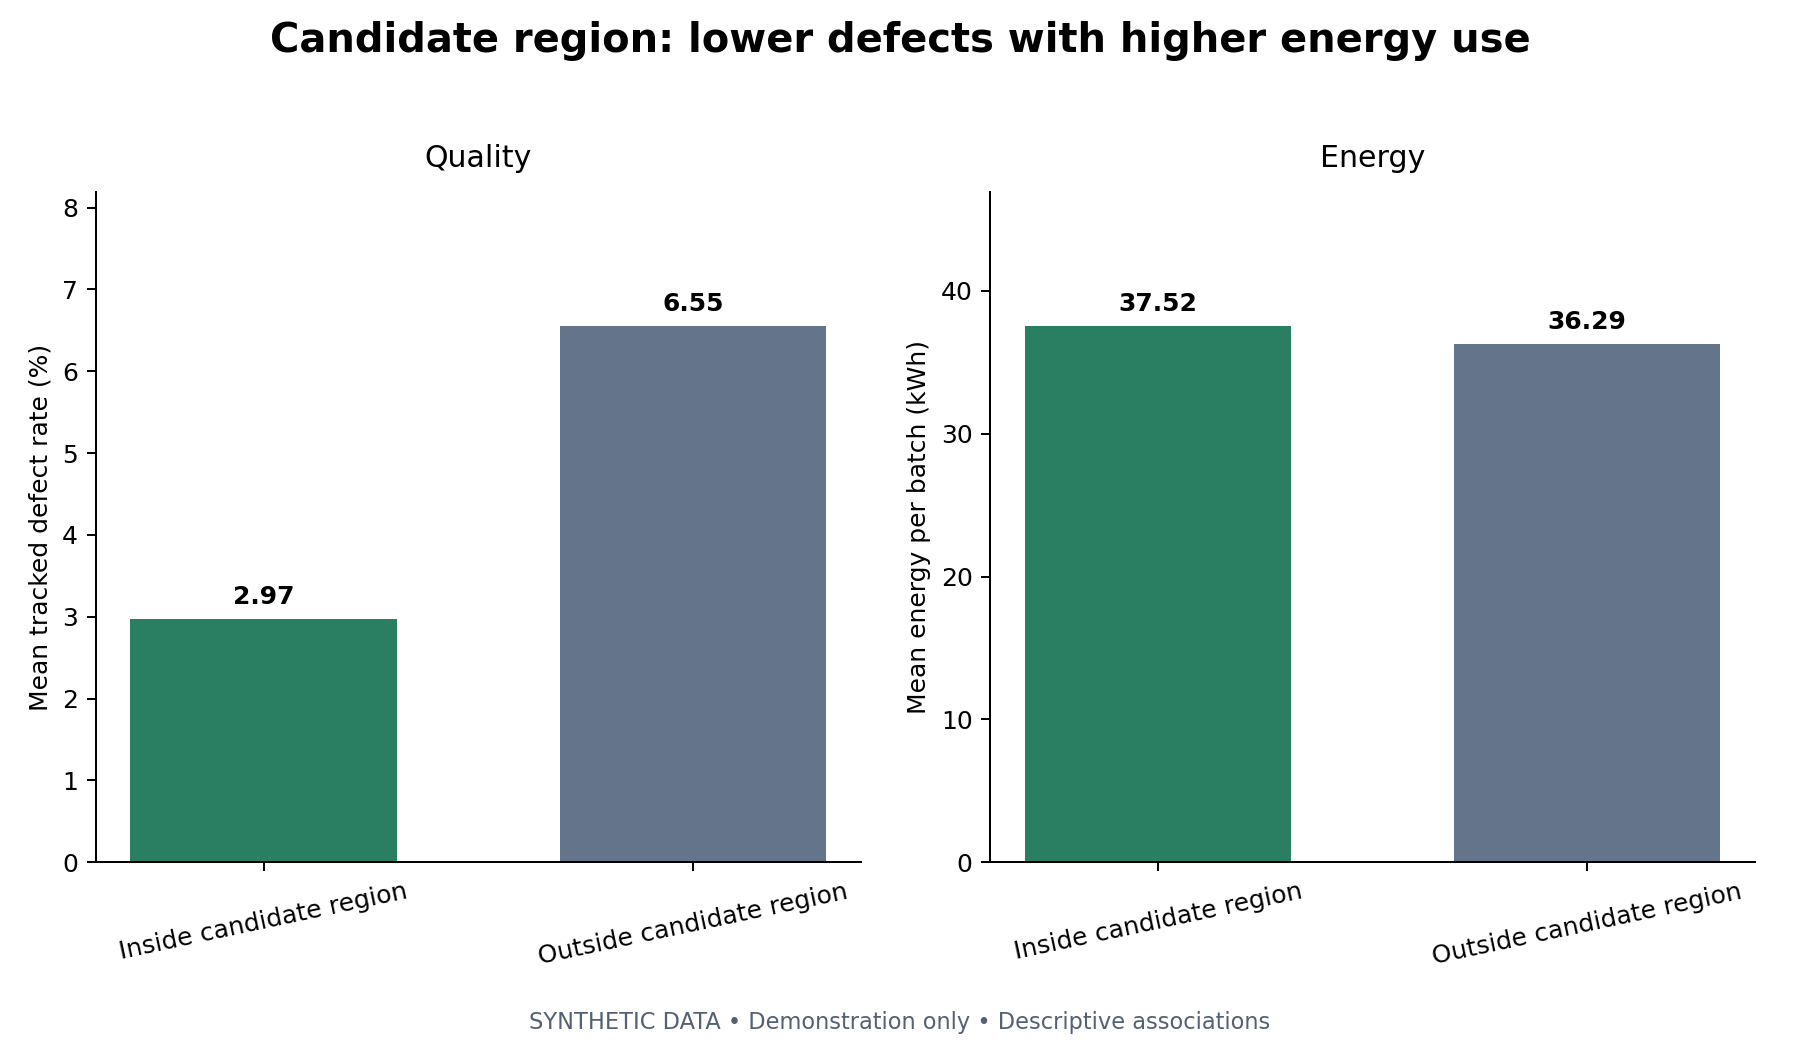

,temperature_C,pressure_MPa,cycle_time_min,yield_percent,defect_rate_percent,energy_kWh
temperature_C,1.000000,0.006459,-0.005335,0.076882,-0.075225,0.704088
pressure_MPa,0.006459,1.000000,0.020462,0.000519,-0.000323,0.116576
cycle_time_min,-0.005335,0.020462,1.000000,0.299858,-0.302887,0.516433
yield_percent,0.076882,0.000519,0.299858,1.000000,-0.994689,0.186794
defect_rate_percent,-0.075225,-0.000323,-0.302887,-0.994689,1.000000,-0.187500
energy_kWh,0.704088,0.116576,0.516433,0.186794,-0.187500,1.000000


In [4]:
for name in ["process_relationships", "correlations", "candidate_region_tradeoff"]:
    display(Image(filename=str(ROOT / "figures" / f"{name}.png")))
display(pd.read_csv(ROOT / "data/processed/correlations.csv", index_col=0))

## 4. Candidate regions and interpretation
Compare predefined screens with their complements. The candidate screen is an illustrative pooled region, not a recommended production window. Check sample sizes and the energy tradeoff before discussing it.

In [5]:
display(pd.read_csv(ROOT / "data/processed/region_comparisons.csv"))
display(pd.read_csv(ROOT / "data/processed/candidate_region_by_material.csv"))

,region,batch_count,yield_percent,defect_rate_percent,energy_kWh
0,candidate_screen,330,95.632,2.971,37.522
1,outside_candidate_screen,2670,92.119,6.549,36.289
2,short_cycle,194,83.624,15.158,31.215
3,outside_short_cycle,2806,93.120,5.533,36.785
4,temperature_tails,301,85.352,13.407,37.208
5,outside_temperature_tails,2699,93.304,5.346,36.338


,material_type,inside_count,outside_count,inside_defect_rate_percent_mean,outside_defect_rate_percent_mean,inside_energy_kWh_mean,outside_energy_kWh_mean
0,A,147,1208,2.695,6.416,37.325,36.256
1,B,115,921,3.276,6.776,37.899,36.621
2,C,68,541,3.054,6.456,37.311,35.799


## Review questions
- How do the material reference temperatures affect the scatterplots?
- Why is the yield–defect correlation partly definitional?
- What could change if batch size, material mix, or process variability changed?
- What real measurements and controlled experiments would be needed to validate a candidate region?

Phase 2 modeling, DOE, SPC, and optimization are deferred until explicit approval.